(256, 256, 3)


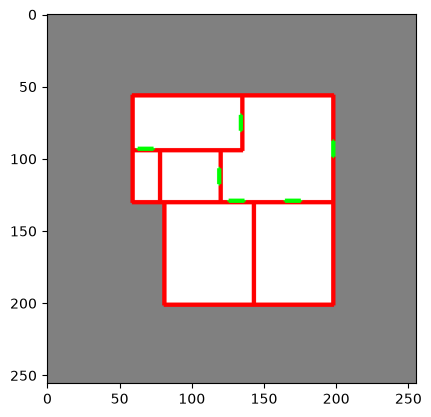

In [ ]:
from datasets import load_dataset
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

ds = load_dataset("metindeder/rplan-floorplan-edited")
for i in range(1):
    image = ds["train"][i]["image"]
    X = np.array(image)
    print(X.shape)
    plt.imshow(X)

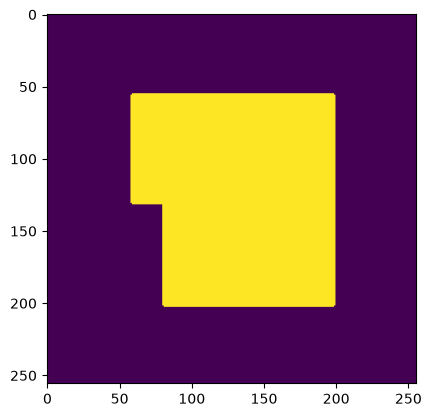

In [74]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def extract_house_mask(pil_img):
    img_rgb = np.array(pil_img.convert("RGB"))
    img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB)
    hsv = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2HSV)
    red1 = cv2.inRange(hsv, (0, 120, 70),   (10, 255, 255))
    red2 = cv2.inRange(hsv, (170, 120, 70), (180, 255, 255))
    wall_mask = cv2.bitwise_or(red1, red2)
    door_mask = cv2.inRange(hsv, (40, 100, 100), (85, 255, 255))
    blueprint_mask = cv2.bitwise_or(wall_mask, door_mask)
    closed = cv2.morphologyEx(blueprint_mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    house_mask = np.zeros_like(closed)
    house_mask = cv2.drawContours(house_mask, contours, -1, 1, thickness=cv2.FILLED)
    return house_mask                                  


ds = load_dataset("metindeder/rplan-floorplan-edited")
pil_img = ds["train"][0]["image"]
house_mask = extract_house_mask(pil_img)
plt.imshow(house_mask)

In [73]:
import numpy as np
import cv2


def door_adjacency(image, min_area=20, return_all=False):
    """
    returns adj (N x N, 0/1, symmetric) with rooms ordered by area, largest first.
    With return_all=True: (adj, room_ids, room_labels, house)
        room_ids[i] = label of the i-th largest room (row/column i of adj)
    Two rooms are connected iff a green door touches both of them.
    """
    # ---- load as RGB array ----
    if isinstance(image, str):
        image = cv2.cvtColor(cv2.imread(image), cv2.COLOR_BGR2RGB)
    elif not isinstance(image, np.ndarray):
        image = np.array(image.convert("RGB"))
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # ---- masks ----
    wall = cv2.bitwise_or(cv2.inRange(hsv, (0, 120, 70), (10, 255, 255)),
                          cv2.inRange(hsv, (170, 120, 70), (180, 255, 255)))
    door = cv2.inRange(hsv, (40, 100, 100), (85, 255, 255))
    blueprint = cv2.bitwise_or(wall, door)

    # ---- house footprint ----
    closed = cv2.morphologyEx(blueprint, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
    cnts, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    house = np.zeros_like(closed)
    cv2.drawContours(house, cnts, -1, 255, thickness=cv2.FILLED)

    # ---- rooms ----
    interior = ((house > 0) & (blueprint == 0)).astype(np.uint8)
    n_labels, room_labels = cv2.connectedComponents(interior)
    counts = np.bincount(room_labels.ravel(), minlength=n_labels)

    # keep valid rooms and sort by area, largest first (ties broken by label)
    room_ids = [l for l in range(1, n_labels) if counts[l] >= min_area]
    room_ids.sort(key=lambda l: (-counts[l], l))

    idx = {l: i for i, l in enumerate(room_ids)}
    N = len(room_ids)

    # ---- dilation radius from wall thickness ----
    dist = cv2.distanceTransform((wall > 0).astype(np.uint8), cv2.DIST_L2, 3)
    r = int(np.ceil(2 * np.percentile(dist[dist > 0], 95))) + 1
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))

    # ---- connect rooms through each door ----
    adj = np.zeros((N, N), dtype=int)
    n_doors, door_labels = cv2.connectedComponents((door > 0).astype(np.uint8))
    for d in range(1, n_doors):
        dil = cv2.dilate((door_labels == d).astype(np.uint8), kernel) > 0
        contact = {l: int(((room_labels == l) & dil).sum()) for l in room_ids}
        touched = sorted((l for l, c in contact.items() if c > 0),
                         key=lambda l: -contact[l])[:2]
        if len(touched) == 2:
            a, b = idx[touched[0]], idx[touched[1]]
            adj[a, b] = adj[b, a] = 1

    return (adj, room_ids, room_labels, house) if return_all else adj

def room_areas(room_labels, room_ids, house_mask=None):
    """
    Areas in the same order as room_ids / adj (largest room first).
    returns dict: 'pixels' (N,), 'percent' (N,), 'total' (px used as denominator)
    """
    counts = np.bincount(room_labels.ravel())
    pixels = np.array([counts[l] for l in room_ids], dtype=np.float32)

    total = float((house_mask > 0).sum()) if house_mask is not None else float(pixels.sum())
    return {"pixels": pixels.astype(int), "percent": 100.0 * pixels / total, "total": int(total)}

def from_adj_to_neighboorhood(adj):
    neighboorhood_matrix = []
    for i, row in enumerate(adj):
        for j, elem in enumerate(row):
            if elem == 1:
                neighboorhood_matrix.append([i, j])

    neighboorhood_matrix = np.array(neighboorhood_matrix).T
    return neighboorhood_matrix

# ---------- usage ----------
adj, room_ids, room_labels, house = door_adjacency("d.png", return_all=True)
areas = room_areas(room_labels, room_ids, house)     # % relative to the whole footprint

sizes = areas["percent"] / 100
neighboorhood = from_adj_to_neighboorhood(adj)  
print(sizes.T)
print(neighboorhood)

[0.3712446  0.22403432 0.16259964 0.04837523 0.04242796]
[[0 0 0 0 1 2 3 4]
 [1 2 3 4 0 0 0 0]]


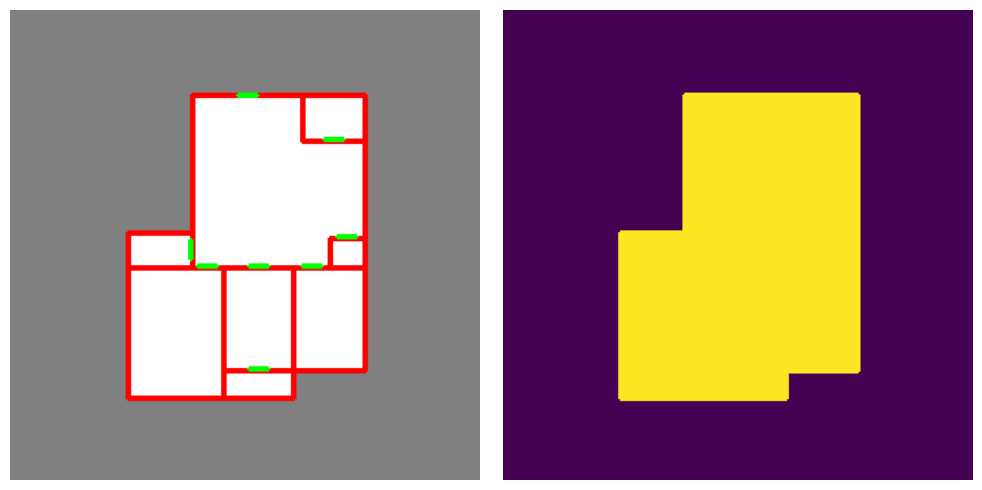

[0, 1]
[0, 2]
[0, 3]
[0, 4]
[0, 5]
[0, 7]
[1, 0]
[2, 0]
[3, 0]
[3, 6]
[4, 0]
[5, 0]
[6, 3]
[7, 0]


In [114]:
import numpy as np
import torch
from torch.utils.data import Dataset
from datasets import load_dataset
from torch_geometric.data import Data

class RPlanDataset(Dataset):
    def __init__(self, split="train", return_graph=False, hf_name="metindeder/rplan-floorplan-edited"):
        self.ds = load_dataset(hf_name)[split]
        self.return_graph = return_graph

    def __len__(self):
        return len(self.ds)

    def _door_adjacency(self, image, min_area=20, return_all=False):
        if isinstance(image, str):
            image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        elif not isinstance(image, np.ndarray):
            image = np.array(image.convert("RGB"))
        hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

        # ---- masks ----
        wall = cv2.bitwise_or(cv2.inRange(hsv, (0, 120, 70), (10, 255, 255)),
                            cv2.inRange(hsv, (170, 120, 70), (180, 255, 255)))
        door = cv2.inRange(hsv, (40, 100, 100), (85, 255, 255))
        blueprint = cv2.bitwise_or(wall, door)

        # ---- house footprint ----
        closed = cv2.morphologyEx(blueprint, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        cnts, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        house = np.zeros_like(closed)
        cv2.drawContours(house, cnts, -1, 255, thickness=cv2.FILLED)

        # ---- rooms ----
        interior = ((house > 0) & (blueprint == 0)).astype(np.uint8)
        n_labels, room_labels = cv2.connectedComponents(interior)
        counts = np.bincount(room_labels.ravel(), minlength=n_labels)

        # keep valid rooms and sort by area, largest first (ties broken by label)
        room_ids = [l for l in range(1, n_labels) if counts[l] >= min_area]
        room_ids.sort(key=lambda l: (-counts[l], l))

        idx = {l: i for i, l in enumerate(room_ids)}
        N = len(room_ids)

        # ---- dilation radius from wall thickness ----
        dist = cv2.distanceTransform((wall > 0).astype(np.uint8), cv2.DIST_L2, 3)
        r = int(np.ceil(2 * np.percentile(dist[dist > 0], 95))) + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (2 * r + 1, 2 * r + 1))

        # ---- connect rooms through each door ----
        adj = np.zeros((N, N), dtype=int)
        n_doors, door_labels = cv2.connectedComponents((door > 0).astype(np.uint8))
        for d in range(1, n_doors):
            dil = cv2.dilate((door_labels == d).astype(np.uint8), kernel) > 0
            contact = {l: int(((room_labels == l) & dil).sum()) for l in room_ids}
            touched = sorted((l for l, c in contact.items() if c > 0),
                            key=lambda l: -contact[l])[:2]
            if len(touched) == 2:
                a, b = idx[touched[0]], idx[touched[1]]
                adj[a, b] = adj[b, a] = 1

        return (adj, room_ids, room_labels, house) if return_all else adj

    def _room_areas(self, room_labels, room_ids, house_mask=None):
        counts = np.bincount(room_labels.ravel())
        pixels = np.array([counts[l] for l in room_ids], dtype=np.float32)

        total = float((house_mask > 0).sum()) if house_mask is not None else float(pixels.sum())
        return {"pixels": pixels.astype(int), "percent": 100.0 * pixels / total, "total": int(total)}


    def _extract_house_mask(self, pil_img):
        img_rgb = np.array(pil_img.convert("RGB"))
        img_rgb = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2RGB)
        hsv = cv2.cvtColor(img_rgb, cv2.COLOR_BGR2HSV)
        red1 = cv2.inRange(hsv, (0, 120, 70),   (10, 255, 255))
        red2 = cv2.inRange(hsv, (170, 120, 70), (180, 255, 255))
        wall_mask = cv2.bitwise_or(red1, red2)
        door_mask = cv2.inRange(hsv, (40, 100, 100), (85, 255, 255))
        blueprint_mask = cv2.bitwise_or(wall_mask, door_mask)
        closed = cv2.morphologyEx(blueprint_mask, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
        contours, _ = cv2.findContours(closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        house_mask = np.zeros_like(closed)
        house_mask = cv2.drawContours(house_mask, contours, -1, 1, thickness=cv2.FILLED)
        return house_mask 

    def _from_adj_to_neighboorhood(self, adj):
        neighboorhood_matrix = []
        for i, row in enumerate(adj):
            for j, elem in enumerate(row):
                if elem == 1:
                    neighboorhood_matrix.append([i, j])
        return neighboorhood_matrix

    def __getitem__(self, idx):
        pil_img = self.ds[idx]["image"]
        house_mask = self._extract_house_mask(pil_img)
        img = np.array(pil_img)

        adj, room_ids, room_labels, house = self._door_adjacency(pil_img, return_all=True)
        areas = self._room_areas(room_labels, room_ids, house)     # % relative to the whole footprint
        sizes = areas["percent"] / 100
        neighboorhood = self._from_adj_to_neighboorhood(adj)  
        return img, house_mask, sizes, neighboorhood

img, mask, sizes, neighboorhood = RPlanDataset()[-5]

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img)
ax[0].axis("off")

ax[1].imshow(mask)
ax[1].axis("off")

plt.tight_layout()
plt.show()

for ns in neighboorhood:
    print(ns)

In [ ]:
def room_areas(room_labels, room_ids, house_mask=None):
    """
    Areas in the same order as room_ids / adj (largest room first).
    returns dict: 'pixels' (N,), 'percent' (N,), 'total' (px used as denominator)
    """
    counts = np.bincount(room_labels.ravel())
    pixels = np.array([counts[l] for l in room_ids], dtype=np.float32)

    total = float((house_mask > 0).sum()) if house_mask is not None else float(pixels.sum())
    return {"pixels": pixels.astype(int), "percent": 100.0 * pixels / total, "total": int(total)}

def from_adj_to_neighboorhood(adj):
    neighboorhood_matrix = []
    for i, row in enumerate(adj):
        for j, elem in enumerate(row):
            if elem == 1:
                neighboorhood_matrix.append([i, j])

    neighboorhood_matrix = np.array(neighboorhood_matrix).T
    return neighboorhood_matrix

# ---------- usage ----------
adj, room_ids, room_labels, house = door_adjacency("d.png", return_all=True)
areas = room_areas(room_labels, room_ids, house)     # % relative to the whole footprint

sizes = areas["percent"] / 100
neighboorhood = from_adj_to_neighboorhood(adj)  
print(sizes.T)
print(neighboorhood)